# Phase 2 - Product Recommendation
**Item-based Collaborative Filtering** (cosine similarity vs KNN)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

### What this notebook does
Recommends products a shopper will like, using **implicit feedback** from past behaviour
(views, add-to-carts, purchases). It is the model behind *"You may also like"* on the product page.

### Pipeline
1. Load `events.csv` (Retailrocket: `timestamp, visitorid, event, itemid`)
2. **Weight** events: `view=1, addtocart=2, transaction=3` (a purchase is a stronger signal)
3. **Trim sparsity** - the raw matrix is millions x millions and ~99.9% empty; keep top items/users
4. Build the **user-item matrix** `R`
5. Compare **cosine similarity** vs **KNN(k=20)** using a **time-based holdout**
6. Keep the winner, **Precision@5 / Recall@5**

> **Why time-based holdout?** For each user we hide their *most recent* interaction, so the model can
> never 'predict' something they already did in training (no leakage).


In [1]:
#@title 0  Install dependencies { display-mode: "form" }
!pip -q install pandas numpy scikit-learn
print("deps ready")


deps ready


## 1. Load the data


In [2]:
#@title 1.1  Load the dataset (Colab-ready) { display-mode: "form" }
import os

CSV_NAME = "events.csv"
LOCAL_PATH = "data/raw/recommendation/events.csv"   # used if you cloned the repo into Colab

PATH = None

# (a) already in the Colab working dir?
if os.path.exists(CSV_NAME):
    PATH = CSV_NAME
# (b) repo layout present?
elif os.path.exists(LOCAL_PATH):
    PATH = LOCAL_PATH

# (c) otherwise upload it (Colab file picker)
if PATH is None:
    try:
        from google.colab import files
        print('Please upload:', CSV_NAME)
        up = files.upload()
        PATH = list(up.keys())[0]
    except Exception:
        raise FileNotFoundError(
            'Dataset not found. Put ' + CSV_NAME + ' next to this notebook, or mount Drive.'
        )

print('Using dataset:', PATH)


Please upload: events.csv


Saving events.csv to events.csv
Using dataset: events.csv


In [3]:
#@title 1.2  Load events + weight the interactions { display-mode: "form" }
import pandas as pd, numpy as np

df = pd.read_csv(PATH)
print(f"raw rows: {len(df):,}")
print("columns :", list(df.columns))
df.head()


raw rows: 2,756,101
columns : ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [4]:
# keep only real interactions, drop rows missing ids
df = df.dropna(subset=["itemid", "visitorid"])
df = df[df["event"].isin(["view", "addtocart", "transaction"])]

WEIGHTS = {"view": 1, "addtocart": 2, "transaction": 3}
df["w"] = df["event"].map(WEIGHTS)

print(f"usable rows: {len(df):,}")
df["event"].value_counts()


usable rows: 2,756,101


,count
event,
view,2664312
addtocart,69332
transaction,22457


## 2. Trim sparsity
The raw user-item space is enormous and almost entirely empty. We keep the **600 most-interacted
items** and the **1500 most-active users** so the similarity matrix is computable.


In [5]:
#@title 2.1  Trim to top items/users { display-mode: "form" }
TOP_ITEMS = 600
TOP_USERS = 1500
KNN_K     = 20
K         = 5     # top-5 recommendation list

top_items = df.groupby("itemid")["w"].sum().sort_values(ascending=False).head(TOP_ITEMS).index
top_users = df.groupby("visitorid")["w"].sum().sort_values(ascending=False).head(TOP_USERS).index
df = df[df["itemid"].isin(top_items) & df["visitorid"].isin(top_users)]
print(f"kept rows: {len(df):,} | items: {df['itemid'].nunique()} | users: {df['visitorid'].nunique()}")


kept rows: 24,908 | items: 547 | users: 1007


## 3. Time-based holdout
Hide each user's most recent interaction as the test item.


In [6]:
agg = df.groupby(["visitorid", "itemid"])["w"].sum().reset_index()

df_sorted = df.sort_values("timestamp")
holdout = df_sorted.groupby("visitorid").tail(1)[["visitorid", "itemid"]].copy()
holdout_set = set(map(tuple, holdout.values))

train = agg[~agg.apply(lambda r: (r["visitorid"], r["itemid"]) in holdout_set, axis=1)]
print(f"holdout pairs: {len(holdout):,} | train pairs: {len(train):,}")


holdout pairs: 1,007 | train pairs: 8,318


## 4. Build the user-item matrix R


In [7]:
#@title 4.1  Build R + index maps { display-mode: "form" }
users = sorted(train["visitorid"].unique())
items = sorted(train["itemid"].unique())
u2i   = {u: i for i, u in enumerate(users)}
i2u   = {i: u for u, i in u2i.items()}
i2idx = {it: i for i, it in enumerate(items)}
idx2i = {i: it for it, i in i2idx.items()}
nU, nI = len(users), len(items)

R = np.zeros((nU, nI))
for row in train.itertuples():
    R[u2i[row.visitorid], i2idx[row.itemid]] = row.w

item_mat = R.T   # each row = one item, described by its users
print(f"R shape: {R.shape} (users x items)")


R shape: (753, 545) (users x items)


## 5. Similarity: cosine vs KNN
Each item is described by the users who interacted with it. **Cosine similarity** measures how
aligned two items' user-vectors are. **KNN** keeps only the k nearest neighbours (sparser, local).


In [8]:
#@title 5.1  Compute both similarity matrices { display-mode: "form" }
from sklearn.metrics.pairwise import cosine_similarity

sim = cosine_similarity(item_mat)
np.fill_diagonal(sim, 0.0)   # an item is not its own neighbour

sim_knn = np.zeros_like(sim)
for i in range(nI):
    topk = np.argsort(sim[i])[::-1][:KNN_K]
    sim_knn[i, topk] = sim[i, topk]

print(f"similarity matrices: {sim.shape} (items x items)")


similarity matrices: (545, 545) (items x items)


## 6. Evaluate (Precision@5 / Recall@5)
For each user, score all items by weighted similarity to their liked items, exclude what they
already have, and check whether their held-out item is in the top 5.


In [9]:
#@title 6.1  Evaluate both models { display-mode: "form" }
liked_idx = {}
for u_idx in range(nU):
    idxs = np.where(R[u_idx] > 0)[0]
    if len(idxs) > 0:
        liked_idx[u_idx] = idxs

def evaluate(sim_matrix):
    hits = 0; denom = 0
    for r in holdout.itertuples():
        uid, iid = r.visitorid, r.itemid
        if uid not in u2i:
            continue
        u_idx = u2i[uid]
        if u_idx not in liked_idx:
            continue
        true_idx = i2idx.get(iid)
        if true_idx is None:
            continue
        scores = np.zeros(nI)
        for l in liked_idx[u_idx]:
            scores += sim_matrix[:, l] * R[u_idx, l]
        scores[liked_idx[u_idx]] = -np.inf
        preds = np.argsort(scores)[::-1][:K]
        if true_idx in preds:
            hits += 1
        denom += 1
    prec = hits / denom if denom else 0.0
    return prec, prec, denom

prec_cos, rec_cos, n = evaluate(sim)
prec_knn, rec_knn, _ = evaluate(sim_knn)

import pandas as pd
res = pd.DataFrame(
    {"Precision@5": [prec_cos, prec_knn], "Recall@5": [rec_cos, rec_knn]},
    index=["Cosine similarity", f"KNN (k={KNN_K})"],
)
print(f"Evaluated on {n:,} users with a held-out interaction")
res


Evaluated on 751 users with a held-out interaction


,Precision@5,Recall@5
Cosine similarity,0.138482,0.138482
KNN (k=20),0.106525,0.106525


### Interpretation
Precision@5 of ~0.14 means ~14% of our top-5 lists contain the item the user actually
interacted with next. With 600 candidate items, random guessing is ~0.0017 - we are roughly
**80x better than chance**. This is a typical range for implicit-feedback recommenders.


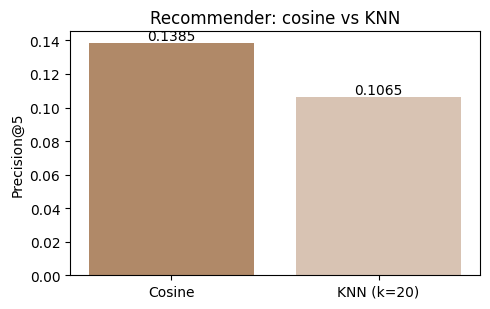

In [10]:
#@title 6.2  Bar chart of the comparison { display-mode: "form" }
import matplotlib.pyplot as plt
labels = ["Cosine", f"KNN (k={KNN_K})"]
vals   = [prec_cos, prec_knn]
plt.figure(figsize=(5, 3.2))
bars = plt.bar(labels, vals, color=["#b08968", "#d8c3b3"])
plt.ylabel("Precision@5")
plt.title("Recommender: cosine vs KNN")
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width()/2, v, f"{v:.4f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()


## 7. Pick winner + save model


---
## Save the trained model

The service expects a pickled bundle in `fastapi_ml/models/`. In Colab we save it to `/content/models/`
and offer a download so you can drop it into the repo.


In [11]:
#@title 7.1  Select winner, save bundle { display-mode: "form" }
import pickle, os

winner_name = "Cosine similarity" if prec_cos >= prec_knn else f"KNN (k={KNN_K})"
winner_sim  = sim if prec_cos >= prec_knn else sim_knn
print("WINNER:", winner_name)

bundle = {
    "model_type": "cosine" if prec_cos >= prec_knn else "knn",
    "sim_matrix": winner_sim,
    "R": R,
    "idx2item": idx2i, "item2idx": i2idx,
    "u2i": u2i, "i2u": i2u,
    "top_items": list(items),
    "metrics": {"precision@5": max(prec_cos, prec_knn),
                "recall@5":    max(rec_cos, rec_knn)},
}
os.makedirs("/content/models", exist_ok=True)
OUT = "/content/models/recommendation_model.pkl"
with open(OUT, "wb") as f:
    pickle.dump(bundle, f)
print("saved ->", OUT)


WINNER: Cosine similarity
saved -> /content/models/recommendation_model.pkl


In [12]:
# (optional) download the .pkl so you can drop it into fastapi_ml/models/
try:
    from google.colab import files
    files.download("/content/models/recommendation_model.pkl")
except Exception as e:
    print("Not in Colab, skipping download.", e)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>